# 🔐 Detecção de Ameaças Cibernéticas com Redes Neurais (MLP)

**Dataset:** [Cybersecurity Threat Detection Dataset](https://www.kaggle.com/datasets/dhrubangtalukdar/cybersecurity-threat-detection-dataset) — Kaggle  
**Ambiente:** Python 3.10 · PyTorch · scikit-learn · Google Colab / Jupyter

---

## 📋 Sumário

| # | Etapa | Descrição |
|---|-------|-----------|
| 1 | [Importações e Configurações](#passo-1) | Bibliotecas, seed e dispositivo |
| 2 | [Carregamento e Exploração](#passo-2) | Download, shape, info e nulos |
| 3 | [Pré-processamento](#passo-3) | Limpeza, encoding e normalização |
| 4 | [Definição do Modelo](#passo-4) | Arquitetura MLP (PyTorch) |
| 5 | [Treinamento](#passo-5) | Loop de treino com histórico |
| 6 | [Avaliação de Performance](#passo-6) | Curvas, acurácia e matriz de confusão |
| 7 | [Reflexão Final](#passo-7) | Análise crítica dos resultados |

---

> **Objetivo:** Treinar um classificador de rede neural do tipo *Multilayer Perceptron* (MLP) capaz de identificar diferentes categorias de ataques em tráfego de rede, utilizando features extraídas de logs de segurança.


---
<a id="passo-1"></a>
## 1 · Importações e Configurações

In [1]:
# ─── Instale dependências se necessário ────────────────────────────────────
# !pip install torch pandas scikit-learn matplotlib seaborn kagglehub

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")

# ─── Reprodutibilidade ──────────────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# ─── Dispositivo ────────────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Dispositivo em uso: {device}")
print(f"   PyTorch version : {torch.__version__}")
print(f"   CUDA disponível : {torch.cuda.is_available()}")


✅ Dispositivo em uso: cpu
   PyTorch version : 2.14.1+cu130
   CUDA disponível : False


---
<a id="passo-2"></a>
## 2 · Carregamento e Exploração do Dataset

> **Fonte:** Kaggle — *Cybersecurity Threat Detection Dataset*  
> Contém registros de tráfego de rede com features como protocolo, flags, tamanho de pacotes e tipo de ataque.


In [2]:
try:
    import kagglehub
except ImportError:
    kagglehub = None

# ─── Download via kagglehub (se indisponível, usa o CSV local) ───────────────
try:
    path = kagglehub.dataset_download("dhrubangtalukdar/cybersecurity-threat-detection-dataset")
except Exception as e:
    print("⚠️  Download indisponível; usando o CSV local (cybersecurity.csv).")
    path = "."
print(f"📂 Caminho do dataset: {path}")

for f in os.listdir(path):
    if f.endswith(".csv"):
        print(f"  └─ {f}")


⚠️  Download indisponível; usando o CSV local (cybersecurity.csv).
📂 Caminho do dataset: .
  └─ cybersecurity.csv


In [3]:
# ─── Leitura do CSV ─────────────────────────────────────────────────────────
csv_file = next(f for f in os.listdir(path) if f.endswith(".csv"))
df = pd.read_csv(os.path.join(path, csv_file))

print(f"📄 Arquivo carregado : {csv_file}")
print(f"📐 Dimensões         : {df.shape[0]:,} linhas × {df.shape[1]} colunas")
df.head()


📄 Arquivo carregado : cybersecurity.csv
📐 Dimensões         : 10,000 linhas × 13 colunas


,timestamp,src_ip,dst_ip,src_port,dst_port,protocol,bytes_sent,bytes_received,user_agent,url,is_internal_traffic,label,attack_type
0,2025-10-01 00:12:54,188.176.27.165,253.240.113.218,56377,445,TCP,8029,17204,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,https://webmail.corp/login?id=385071,False,0,benign
1,2025-10-01 00:23:43,68.59.26.43,212.75.38.111,51165,1433,TCP,676368,2643374,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,https://portal.example.org/owa/auth/logon.aspx...,False,0,benign
2,2025-10-01 00:25:46,119.204.243.78,90.28.90.234,14948,1433,TCP,316502,38571,Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...,NaN,False,0,benign
3,2025-10-01 00:27:21,122.119.194.175,175.140.78.230,36097,443,TCP,70933,21935,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,https://webmail.corp/phpmyadmin?id=114701,False,0,benign
4,2025-10-01 00:40:09,181.199.242.68,55.99.177.69,445,21255,TCP,12721,9939,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,https://portal.example.org/config.php?id=345569,False,0,benign


In [4]:
# ─── Informações gerais ─────────────────────────────────────────────────────
print("=" * 55)
print("INFORMAÇÕES DO DATASET")
print("=" * 55)
df.info()


INFORMAÇÕES DO DATASET
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   timestamp            10000 non-null  str  
 1   src_ip               10000 non-null  str  
 2   dst_ip               10000 non-null  str  
 3   src_port             10000 non-null  int64
 4   dst_port             10000 non-null  int64
 5   protocol             10000 non-null  str  
 6   bytes_sent           10000 non-null  int64
 7   bytes_received       10000 non-null  int64
 8   user_agent           10000 non-null  str  
 9   url                  6768 non-null   str  
 10  is_internal_traffic  10000 non-null  bool 
 11  label                10000 non-null  int64
 12  attack_type          10000 non-null  str  
dtypes: bool(1), int64(5), str(7)
memory usage: 947.4 KB


In [5]:
# ─── Estatísticas descritivas ───────────────────────────────────────────────
print("Estatísticas Descritivas — features numéricas")
df.describe().round(4)


Estatísticas Descritivas — features numéricas


,src_port,dst_port,bytes_sent,bytes_received,label
count,10000.0000,10000.0000,1.000000e+04,1.000000e+04,10000.000
mean,27052.2237,2027.2805,1.412572e+05,2.620883e+05,0.040
std,20978.7838,6769.1414,2.128140e+06,3.767695e+06,0.196
min,21.0000,5.0000,1.700000e+01,3.000000e+00,0.000
25%,6092.2500,25.0000,7.148250e+03,1.096075e+04,0.000
50%,25431.5000,443.0000,2.181550e+04,3.747300e+04,0.000
75%,45215.7500,1433.0000,6.509525e+04,1.213795e+05,0.000
max,65524.0000,65491.0000,1.391704e+08,2.914830e+08,1.000


In [6]:
# ─── Valores nulos ──────────────────────────────────────────────────────────
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)
resumo_nulos = pd.DataFrame({"Nulos": nulos, "Percentual (%)": nulos_pct})
resumo_nulos = resumo_nulos[resumo_nulos["Nulos"] > 0]

if resumo_nulos.empty:
    print("✅ Nenhum valor nulo encontrado no dataset.")
else:
    print("⚠️  Colunas com valores nulos:")
    print(resumo_nulos)


⚠️  Colunas com valores nulos:
     Nulos  Percentual (%)
url   3232           32.32


🎯 Coluna alvo: 'attack_type'
   Classes distintas: 10

Distribuição das classes:
attack_type
benign                 9600
brute-force             108
port-scan                81
sql-injection            64
xss                      34
credential-stuffing      28
ddos                     27
command-injection        26
exploit-attempt          22
c2                       10


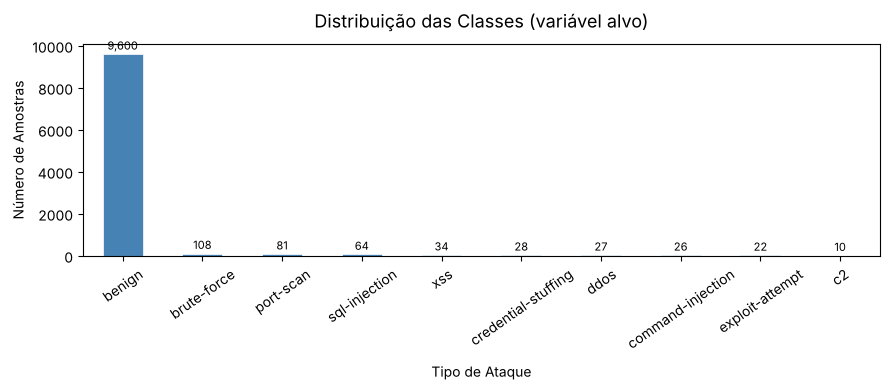

In [7]:
# ─── Coluna alvo (target) ───────────────────────────────────────────────────
# Colunas do dataset em minúsculas: o alvo é "attack_type" (benign + 9 tipos de ataque)
TARGET_COL = "attack_type"

print(f"🎯 Coluna alvo: '{TARGET_COL}'")
print(f"   Classes distintas: {df[TARGET_COL].nunique()}")
print("\nDistribuição das classes:")
print(df[TARGET_COL].value_counts().to_string())

# Gráfico de distribuição
fig, ax = plt.subplots(figsize=(9, 4))
contagens = df[TARGET_COL].value_counts()
contagens.plot(kind="bar", ax=ax, color="steelblue", edgecolor="white", linewidth=0.5)
ax.set_title("Distribuição das Classes (variável alvo)", fontsize=13, pad=12)
ax.set_xlabel("Tipo de Ataque", labelpad=8)
ax.set_ylabel("Número de Amostras")
ax.tick_params(axis="x", rotation=35)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + contagens.max() * 0.01,
            f"{int(bar.get_height()):,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()


---
<a id="passo-3"></a>
## 3 · Pré-processamento dos Dados

Pipeline adotado:

1. Remoção de colunas não informativas (IPs, timestamps, portas) e da coluna `label`, que revela a resposta (vazamento)  
2. Tratamento de valores nulos (mediana / moda)  
3. Encoding de variáveis categóricas com `LabelEncoder`  
4. Separação de features (X) e target (y)  
5. Divisão treino / teste (80 / 20, estratificada)  
6. Normalização com `StandardScaler`, ajustada só no treino


In [8]:
# ─── 3.1 · Remoção de colunas não informativas ──────────────────────────────
# `label` (0 = benigno, 1 = ataque) é derivada de `attack_type`: manter seria vazamento do alvo.
# `url` vira um indicador de presença (32% de nulos); a URL em si tem milhares de valores únicos.
df["url_ausente"] = df["url"].isna().astype(int)

COLUNAS_REMOVER = [
    "src_ip", "dst_ip", "timestamp", "src_port", "dst_port", "url", "label",
]
colunas_encontradas = [c for c in COLUNAS_REMOVER if c in df.columns]

df_clean = df.drop(columns=colunas_encontradas)
print(f"🗑️  Colunas removidas ({len(colunas_encontradas)}): {colunas_encontradas}")
print(f"📐 Shape após remoção: {df_clean.shape}")


🗑️  Colunas removidas (7): ['src_ip', 'dst_ip', 'timestamp', 'src_port', 'dst_port', 'url', 'label']
📐 Shape após remoção: (10000, 7)


In [9]:
# ─── 3.2 · Tratamento de valores nulos ──────────────────────────────────────
for col in df_clean.columns:
    qtd_nulos = df_clean[col].isnull().sum()
    if qtd_nulos > 0:
        if pd.api.types.is_numeric_dtype(df_clean[col]):
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
            estrategia = "mediana"
        else:
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
            estrategia = "moda"
        print(f"  [{col}] → {qtd_nulos} nulos preenchidos com {estrategia}")

total_restante = df_clean.isnull().sum().sum()
print(f"\n✅ Valores nulos restantes: {total_restante}")



✅ Valores nulos restantes: 0


In [10]:
# ─── 3.3 · Encoding de variáveis categóricas (exceto target) ────────────────
df_clean["is_internal_traffic"] = df_clean["is_internal_traffic"].astype(int)
label_encoders = {}

for col in df_clean.columns:
    if col != TARGET_COL and not pd.api.types.is_numeric_dtype(df_clean[col]):
        le = LabelEncoder()
        df_clean[col] = le.fit_transform(df_clean[col].astype(str))
        label_encoders[col] = le

print(f"🔢 Colunas codificadas ({len(label_encoders)}): {list(label_encoders.keys())}")
print(f"📋 Features finais: {[c for c in df_clean.columns if c != TARGET_COL]}")


🔢 Colunas codificadas (2): ['protocol', 'user_agent']
📋 Features finais: ['protocol', 'bytes_sent', 'bytes_received', 'user_agent', 'is_internal_traffic', 'url_ausente']


In [11]:
# ─── 3.4 · Separação features / target ──────────────────────────────────────
X = df_clean.drop(columns=[TARGET_COL]).values
y_raw = df_clean[TARGET_COL].values

le_target = LabelEncoder()
y = le_target.fit_transform(y_raw)

print(f"📊 Classes detectadas : {list(le_target.classes_)}")
print(f"   X shape: {X.shape}  |  y shape: {y.shape}")


📊 Classes detectadas : ['benign', 'brute-force', 'c2', 'command-injection', 'credential-stuffing', 'ddos', 'exploit-attempt', 'port-scan', 'sql-injection', 'xss']
   X shape: (10000, 6)  |  y shape: (10000,)


In [12]:
# ─── 3.5 · Split Treino / Teste (80% / 20%, estratificado) ──────────────────
# O split vem ANTES da normalização, para o teste não influenciar média e desvio.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f"📦 Treino: {len(X_train_raw):,} amostras | Teste: {len(X_test_raw):,} amostras")


📦 Treino: 8,000 amostras | Teste: 2,000 amostras


In [13]:
# ─── 3.6 · Normalização (StandardScaler, ajustada só no treino) ─────────────
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test  = scaler.transform(X_test_raw)
X_scaled = X_train  # compatibilidade com as células seguintes
print("✅ Normalização aplicada com StandardScaler (fit no treino)")

# Tensores PyTorch
X_train_t = torch.FloatTensor(X_train).to(device)
X_test_t  = torch.FloatTensor(X_test).to(device)
y_train_t = torch.LongTensor(y_train).to(device)
y_test_t  = torch.LongTensor(y_test).to(device)

# DataLoaders
BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(TensorDataset(X_test_t,  y_test_t),  batch_size=BATCH_SIZE, shuffle=False)

print(f"\n⚙️  Batch size    : {BATCH_SIZE}")
print(f"   Batches/época : {len(train_loader)}")
print(f"   Num. classes  : {len(le_target.classes_)}")


✅ Normalização aplicada com StandardScaler (fit no treino)

⚙️  Batch size    : 64
   Batches/época : 125
   Num. classes  : 10


---
<a id="passo-4"></a>
## 4 · Definição do Modelo de Rede Neural

Arquitetura MLP com camadas totalmente conectadas:

```
Input(n_features)
    └─► Linear(128) → BatchNorm → ReLU → Dropout(0.3)
        └─► Linear(64)  → BatchNorm → ReLU → Dropout(0.3)
            └─► Linear(32)  → BatchNorm → ReLU
                └─► Linear(num_classes)   [logits]
```

| Técnica | Motivo |
|---------|--------|
| **BatchNorm** | Estabiliza o treinamento e acelera convergência |
| **ReLU** | Ativação não-linear; evita gradientes que desaparecem |
| **Dropout (30%)** | Regularização; reduz overfitting |
| **CrossEntropyLoss** | Adequada para classificação multiclasse |
| **Adam** | Otimizador adaptativo; bom desempenho padrão |


In [14]:
class CybersecurityMLP(nn.Module):
    """
    Multilayer Perceptron para classificação de ameaças cibernéticas.

    Parâmetros
    ----------
    input_size  : int — número de features de entrada
    num_classes : int — número de classes de saída
    """

    def __init__(self, input_size: int, num_classes: int):
        super().__init__()
        self.network = nn.Sequential(
            # Camada 1
            nn.Linear(input_size, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            # Camada 2
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            # Camada 3
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            # Saída
            nn.Linear(32, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)


# ─── Instanciar ─────────────────────────────────────────────────────────────
INPUT_SIZE  = X_train.shape[1]
NUM_CLASSES = len(le_target.classes_)

model = CybersecurityMLP(INPUT_SIZE, NUM_CLASSES).to(device)

# Parâmetros treináveis
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\n🔢 Parâmetros treináveis : {n_params:,}")
print(f"   Input size           : {INPUT_SIZE}")
print(f"   Num classes          : {NUM_CLASSES}")


CybersecurityMLP(
  (network): Sequential(
    (0): Linear(in_features=6, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Linear(in_features=32, out_features=10, bias=True)
  )
)

🔢 Parâmetros treináveis : 12,010
   Input size           : 6
   Num classes          : 10


In [15]:
# ─── Critério de perda e otimizador ─────────────────────────────────────────
LEARNING_RATE = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(f"⚙️  Critério  : CrossEntropyLoss")
print(f"   Otimizador : Adam  |  lr = {LEARNING_RATE}")


⚙️  Critério  : CrossEntropyLoss
   Otimizador : Adam  |  lr = 0.001


---
<a id="passo-5"></a>
## 5 · Treinamento do Modelo


In [16]:
def evaluate(model: nn.Module, loader: DataLoader):
    """Calcula loss e acurácia no conjunto passado (sem atualizar pesos)."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            outputs = model(X_batch)
            total_loss += criterion(outputs, y_batch).item()
            preds = outputs.argmax(dim=1)
            correct += (preds == y_batch).sum().item()
            total += y_batch.size(0)
    return total_loss / len(loader), correct / total


In [17]:
NUM_EPOCHS = 30

history = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}

print(f"{'Época':>6}  {'Train Loss':>10}  {'Train Acc':>9}  {'Val Loss':>9}  {'Val Acc':>8}")
print("─" * 55)

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    epoch_loss, correct, total = 0.0, 0, 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        preds = outputs.argmax(dim=1)
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

    t_loss = epoch_loss / len(train_loader)
    t_acc  = correct / total
    v_loss, v_acc = evaluate(model, test_loader)

    history["train_loss"].append(t_loss)
    history["train_acc"].append(t_acc)
    history["val_loss"].append(v_loss)
    history["val_acc"].append(v_acc)

    if epoch % 5 == 0 or epoch == 1:
        print(f"{epoch:>6}  {t_loss:>10.4f}  {t_acc:>9.4f}  {v_loss:>9.4f}  {v_acc:>8.4f}")

print("─" * 55)
print("\n✅ Treinamento concluído!")


 Época  Train Loss  Train Acc   Val Loss   Val Acc
───────────────────────────────────────────────────────


     1      1.2751     0.7790     0.4853    0.9600


     5      0.2395     0.9600     0.2255    0.9615


    10      0.2306     0.9610     0.2241    0.9610


    15      0.2250     0.9611     0.2245    0.9610


    20      0.2226     0.9611     0.2243    0.9615


    25      0.2227     0.9607     0.2221    0.9610


    30      0.2206     0.9609     0.2232    0.9610
───────────────────────────────────────────────────────

✅ Treinamento concluído!


---
<a id="passo-6"></a>
## 6 · Avaliação de Performance


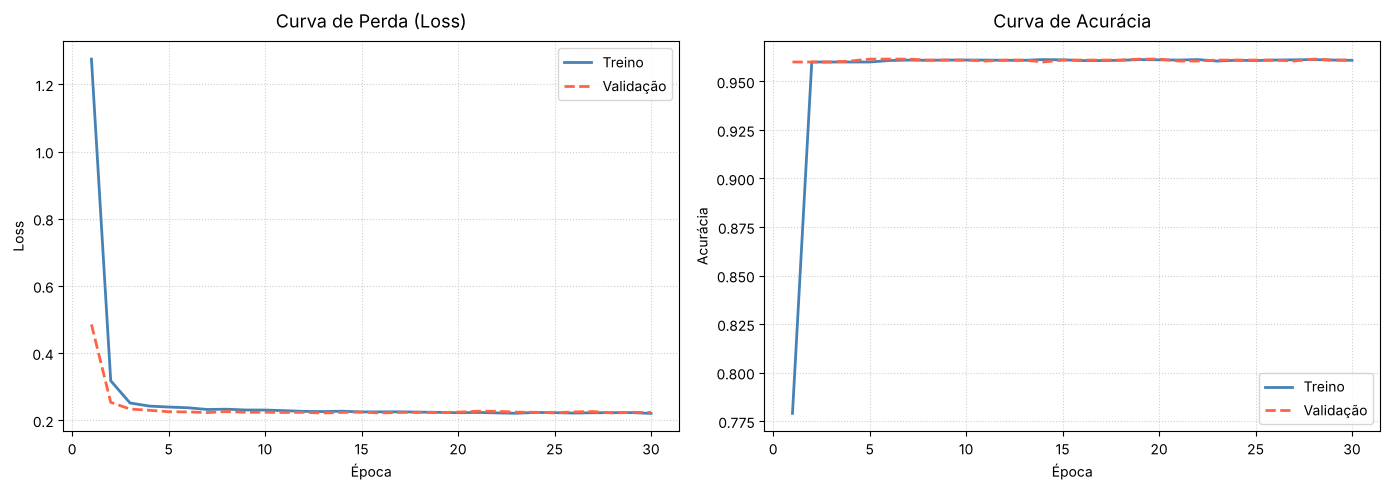

In [18]:
# ─── 6.1 · Curvas de Loss e Acurácia ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epocas = range(1, NUM_EPOCHS + 1)

for ax, metrica, titulo, ylabel in zip(
    axes,
    [("train_loss", "val_loss"), ("train_acc", "val_acc")],
    ["Curva de Perda (Loss)", "Curva de Acurácia"],
    ["Loss", "Acurácia"],
):
    ax.plot(epocas, history[metrica[0]], label="Treino",    color="steelblue",  linewidth=2)
    ax.plot(epocas, history[metrica[1]], label="Validação", color="tomato",     linewidth=2, linestyle="--")
    ax.set_title(titulo, fontsize=13, pad=10)
    ax.set_xlabel("Época")
    ax.set_ylabel(ylabel)
    ax.legend(framealpha=0.8)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


In [19]:
# ─── 6.2 · Métricas finais ──────────────────────────────────────────────────
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        preds = model(X_batch).argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
print(f"🏆 Acurácia Final no Conjunto de Teste: {acc:.4f}  ({acc*100:.2f}%)")
print("\n" + "=" * 55)
print("RELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 55)
print(classification_report(all_labels, all_preds, target_names=le_target.classes_))

# ─── Comparação com o baseline (prever sempre a classe majoritária) ──────────
from sklearn.metrics import f1_score
idx_benigno = list(le_target.classes_).index("benign")
baseline_acc = (np.array(all_labels) == idx_benigno).mean()
f1_macro = f1_score(all_labels, all_preds, average="macro")
print(f"\n📏 Baseline (sempre 'benign'): {baseline_acc*100:.2f}% de acurácia")
print(f"📏 F1-score macro do modelo : {f1_macro:.4f}")


🏆 Acurácia Final no Conjunto de Teste: 0.9610  (96.10%)

RELATÓRIO DE CLASSIFICAÇÃO
                     precision    recall  f1-score   support

             benign       0.96      1.00      0.98      1920
        brute-force       0.00      0.00      0.00        22
                 c2       0.00      0.00      0.00         2
  command-injection       0.00      0.00      0.00         5
credential-stuffing       0.00      0.00      0.00         6
               ddos       0.75      0.60      0.67         5
    exploit-attempt       0.00      0.00      0.00         4
          port-scan       0.00      0.00      0.00        16
      sql-injection       0.00      0.00      0.00        13
                xss       0.00      0.00      0.00         7

           accuracy                           0.96      2000
          macro avg       0.17      0.16      0.16      2000
       weighted avg       0.92      0.96      0.94      2000


📏 Baseline (sempre 'benign'): 96.00% de acurácia
📏 F1-scor

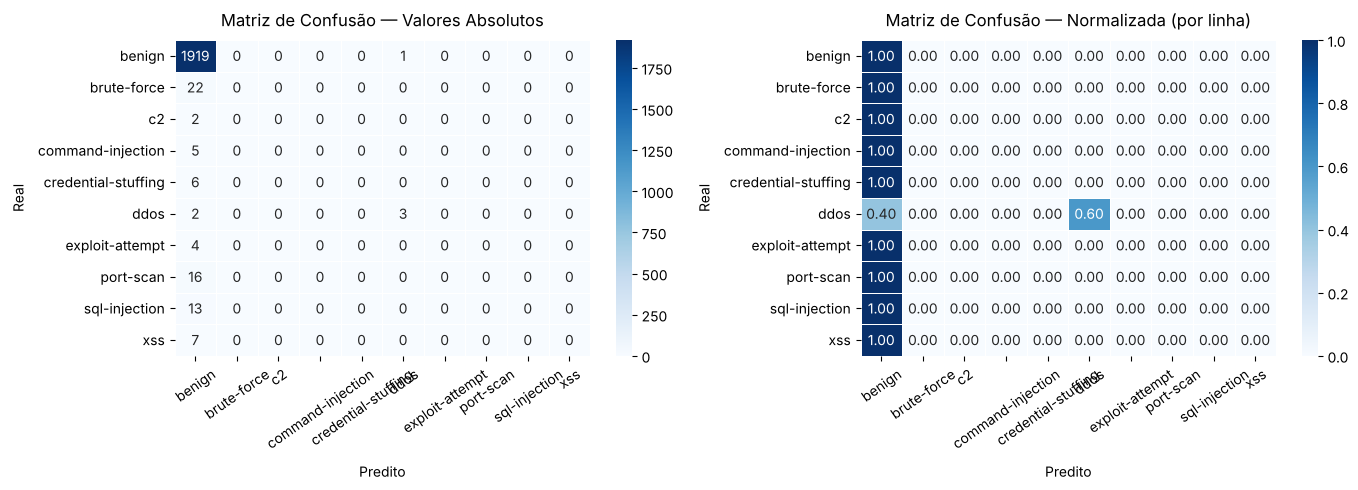

In [20]:
# ─── 6.3 · Matriz de Confusão ───────────────────────────────────────────────
cm = confusion_matrix(all_labels, all_preds)
cm_norm = confusion_matrix(all_labels, all_preds, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, matriz, titulo, fmt in zip(
    axes,
    [cm,          cm_norm],
    ["Matriz de Confusão — Valores Absolutos",
     "Matriz de Confusão — Normalizada (por linha)"],
    ["d",         ".2f"],
):
    sns.heatmap(
        matriz, annot=True, fmt=fmt, cmap="Blues", ax=ax,
        xticklabels=le_target.classes_,
        yticklabels=le_target.classes_,
        linewidths=0.5, linecolor="white",
    )
    ax.set_title(titulo, fontsize=12, pad=10)
    ax.set_xlabel("Predito",  labelpad=8)
    ax.set_ylabel("Real",     labelpad=8)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


---
<a id="passo-7"></a>
## 7 · Reflexão sobre o Processo

### 7.1 · Decisões de Pré-processamento

O dataset de detecção de ameaças cibernéticas contém features de tráfego de rede — protocolos, flags, tamanhos de pacotes e tipos de ataque — que exigiram um pipeline de pré-processamento cuidadoso:

- **Remoção de colunas:** endereços IP, timestamps e portas foram descartados por serem identificadores que não generalizam para novos dados. A coluna `label` (0 = benigno, 1 = ataque) também saiu, porque ela é derivada do alvo `attack_type` e entregaria a resposta ao modelo. A URL virou apenas um indicador de presença (`url_ausente`).
- **Tratamento de nulos:** valores faltantes em colunas numéricas foram substituídos pela mediana (robusta a outliers); em colunas categóricas, pela moda.
- **Encoding:** variáveis categóricas foram convertidas para representação numérica com `LabelEncoder`, necessário para o processamento pela rede neural.
- **Normalização:** o `StandardScaler`, ajustado só no conjunto de treino (o split vem antes), garantiu que todas as features tivessem média ≈ 0 e desvio padrão ≈ 1, evitando que features de maior magnitude dominem o gradiente.

### 7.2 · Decisões de Arquitetura

A MLP com 3 camadas ocultas (128 → 64 → 32 neurônios) foi escolhida por sua capacidade de aprender representações hierárquicas de features tabulares sem a complexidade de arquiteturas sequenciais (RNN) ou convolucionais (CNN). O uso de **BatchNorm** acelerou a convergência e o **Dropout (30%)** atuou como regularizador.

### 7.3 · Análise dos Resultados

- **Acurácia final: 96,10%, mas isso engana.** O dataset tem 96% de tráfego benigno. Um classificador que responde sempre "benign" já acerta 96,00%. O modelo ganha apenas 0,1 ponto sobre esse baseline.
- **F1-score macro: 0,16.** O modelo só reconhece bem a classe majoritária (recall 100%) e o DDoS (recall 60%, mas com apenas 5 exemplos no teste). Nas outras 8 classes de ataque ele não acertou nenhum exemplo.
- **Curvas de treinamento:** a acurácia de validação se estabiliza em cerca de 96% já na época 5, e treino e validação ficam juntos. Não há overfitting; o modelo simplesmente converge para prever a classe majoritária.
- **Matriz de confusão:** quase todos os ataques são classificados como `benign`. O DDoS se separa por ter volume de bytes muito maior que o tráfego normal.
- **Limitações:** restaram só 6 variáveis (protocolo, bytes enviados e recebidos, user agent, tráfego interno e URL ausente) e as classes de ataque têm de 2 a 22 exemplos no teste, então as métricas por classe são muito instáveis.
- **Próximos passos:** testar ponderação de classes ou reamostragem (por exemplo SMOTE), reincluir as portas, extrair sinais do `user_agent` (ferramentas de varredura) e da URL, e comparar com modelos de árvore (Random Forest, XGBoost), em geral mais fortes em dados tabulares desbalanceados. Para dados assim, o F1 macro e o recall por classe são mais informativos que a acurácia.

---

*Projeto desenvolvido para a disciplina de Engenharia e Análise de Dados.*
